# Actividad 3: Aprendizaje supervisado – Clasificación de segmentos de vivienda

## 0. Pregunta de negocio y construcción automática del DataFrame

### Pregunta de negocio

¿Qué características socioeconómicas y geográficas permiten identificar si una zona residencial de California pertenece a un segmento de valor de vivienda bajo, medio o alto?

Esta pregunta busca apoyar a analistas del mercado inmobiliario e inversionistas en la identificación de zonas residenciales según sus características y valor de vivienda.

### Beneficiarios y decisiones

- Analistas inmobiliarios: identificar características asociadas con diferentes segmentos de valor.
- Inversionistas: apoyar la selección y evaluación de zonas residenciales.
- Entidades de planificación: analizar las diferencias socioeconómicas y geográficas entre zonas.

### Identificación del dataset

- Nombre: California Housing.
- Plataforma: Hugging Face Datasets.
- Identificador: BrianSuToronto/california_housing.
- URL: https://huggingface.co/datasets/BrianSuToronto/california_housing
- Split: train.
- Registros originales: 20.640.
- Columnas originales: 9.

### Justificación del dataset seleccionado

El conjunto de datos `BrianSuToronto/california_housing` fue seleccionado porque contiene información relacionada con las características socioeconómicas, habitacionales y geográficas de diferentes zonas residenciales de California.

Sus variables permiten analizar factores como el ingreso mediano de los hogares, la antigüedad de las viviendas, el promedio de habitaciones, la población y la ubicación geográfica.

Esta información resulta pertinente para el proyecto porque permite estudiar las características que pueden estar relacionadas con el valor de las viviendas y utilizarlas para construir un modelo de clasificación que identifique tres segmentos: Bajo, Medio y Alto.

Por lo tanto, el dataset proporciona información suficiente para abordar la pregunta de negocio planteada mediante técnicas de análisis de datos y aprendizaje automático.


### Importación del módulo existente

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

while ROOT != ROOT.parent and not (ROOT / "src" / "clases").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases import HFDatasetLoader, Reportes

import pandas as pd
from IPython.display import display

print("Proyecto:", ROOT)
print("Python:", sys.version)
print("Módulos reutilizados correctamente.")

/workspaces/Machine-Learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: /workspaces/Machine-Learning
Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Módulos reutilizados correctamente.


### Configuración y carga

In [2]:
DATASET = "BrianSuToronto/california_housing"
SPLIT = "train"

loader = HFDatasetLoader(
    dataset_name=DATASET,
    split=SPLIT
)

df = loader.load()

print("Dataset cargado correctamente.")
print("Identificador:", DATASET)
print("Split:", SPLIT)

Dataset cargado correctamente.
Identificador: BrianSuToronto/california_housing
Split: train


### Construcción automática del DataFrame

La obtención de los datos se realizó mediante código utilizando la clase `HFDatasetLoader`, desarrollada previamente en el proyecto.

Se utilizó el identificador del dataset de Hugging Face y el split `train`, permitiendo obtener los datos directamente desde la plataforma y convertirlos en un DataFrame de Pandas.

Este procedimiento automatiza la obtención de la información y evita depender de la descarga manual de archivos o de rutas locales para cargar el conjunto de datos.

Posteriormente, se renombraron las columnas al español y se construyó la variable objetivo `Categoria_valor`, obteniendo un DataFrame transformado de 20.640 registros y 10 columnas.

### Evidencia del DataFrame

In [3]:
print("DIMENSIONES DEL DATAFRAME")
print("=" * 50)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

print("\nCOLUMNAS")
display(pd.DataFrame({
    "Columna": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores nulos": df.isna().sum().values
}))

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nPRIMERAS CINCO FILAS")
display(df.head())

DIMENSIONES DEL DATAFRAME
Filas: 20,640
Columnas: 9

COLUMNAS


,Columna,Tipo de dato,Valores nulos
0,MedInc,float64,0
1,HouseAge,float64,0
2,AveRooms,float64,0
3,AveBedrms,float64,0
4,Population,float64,0
5,AveOccup,float64,0
6,Latitude,float64,0
7,Longitude,float64,0
8,MedHouseVal,float64,0



INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

PRIMERAS CINCO FILAS


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Reutilizar la clase de reportes

In [4]:
reporte = Reportes()

reporte.imprimir_reporte(df)

REPORTE DEL DATAFRAME
Filas: 20640
Columnas: 9
Duplicados: 0

Columnas y tipos:
- MedInc: float64
- HouseAge: float64
- AveRooms: float64
- AveBedrms: float64
- Population: float64
- AveOccup: float64
- Latitude: float64
- Longitude: float64
- MedHouseVal: float64

Valores nulos por columna:
- MedInc: 0
- HouseAge: 0
- AveRooms: 0
- AveBedrms: 0
- Population: 0
- AveOccup: 0
- Latitude: 0
- Longitude: 0
- MedHouseVal: 0

Estadísticas numéricas:
          MedInc   HouseAge   AveRooms  AveBedrms  Population   AveOccup   Latitude  Longitude  MedHouseVal
count  20640.000  20640.000  20640.000  20640.000   20640.000  20640.000  20640.000  20640.000    20640.000
mean       3.871     28.639      5.429      1.097    1425.477      3.071     35.632   -119.570        2.069
std        1.900     12.586      2.474      0.474    1132.462     10.386      2.136      2.004        1.154
min        0.500      1.000      0.846      0.333       3.000      0.692     32.540   -124.350        0.150
25%        

## 0.1. Construcción de la variable objetivo de clasificación

Se transforma el valor mediano de las viviendas en tres categorías mediante terciles, manteniendo la misma metodología de la actividad anterior.

In [5]:

# Construcción de la variable objetivo de clasificación

# 1. Renombrar las columnas originales al español
nombres_columnas = {
    "MedInc": "Ingreso_mediano",
    "HouseAge": "Edad_vivienda",
    "AveRooms": "Promedio_habitaciones",
    "AveBedrms": "Promedio_dormitorio_hogar",
    "Population": "Poblacion",
    "AveOccup": "Promedio_ocupacion",
    "Latitude": "Latitud",
    "Longitude": "Longitud",
    "MedHouseVal": "Valor_mediano_vivienda",
}

df_transformado = df.rename(columns=nombres_columnas).copy()

# 2. Crear las tres categorías mediante terciles
df_modelo = df_transformado.assign(
    Categoria_valor=pd.qcut(
        df_transformado["Valor_mediano_vivienda"],
        q=3,
        labels=["Bajo", "Medio", "Alto"]
    )
)

# 3. Mostrar distribución de categorías
print("Distribución de categorías:")
display(df_modelo["Categoria_valor"].value_counts())

# 4. Mostrar los rangos de cada categoría
print("\nRangos de valores por categoría:")
rangos = (
    df_modelo.groupby("Categoria_valor", observed=False)
    ["Valor_mediano_vivienda"]
    .agg(["min", "max"])
)
display(rangos)

# 5. Verificar dimensiones y estructura
print("\nDimensiones del DataFrame original:", df.shape)
print("Dimensiones del DataFrame transformado:", df_modelo.shape)

print("\nPrimeros registros:")
display(df_modelo.head())


Distribución de categorías:


Categoria_valor
Bajo     6884
Alto     6880
Medio    6876
Name: count, dtype: int64


Rangos de valores por categoría:


,min,max
Categoria_valor,,
Bajo,0.14999,1.41400
Medio,1.41500,2.30300
Alto,2.30400,5.00001



Dimensiones del DataFrame original: (20640, 9)
Dimensiones del DataFrame transformado: (20640, 10)

Primeros registros:


,Ingreso_mediano,Edad_vivienda,Promedio_habitaciones,Promedio_dormitorio_hogar,Poblacion,Promedio_ocupacion,Latitud,Longitud,Valor_mediano_vivienda,Categoria_valor
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,Alto
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,Alto
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,Alto
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,Alto
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,Alto


### Construcción de la variable objetivo

Para desarrollar el problema de clasificación, se construyó una nueva variable denominada `Categoria_valor`, tomando como referencia la columna original `MedHouseVal`, renombrada como `Valor_mediano_vivienda`.

Se utilizó la función `pd.qcut()` de Pandas con tres cuantiles (terciles), distribuyendo los registros en tres categorías:

- **Bajo:** representa el tercio inferior de los valores de vivienda.
- **Medio:** representa el tercio intermedio.
- **Alto:** representa el tercio superior.

Se seleccionó esta técnica porque permite dividir los registros en grupos con cantidades de observaciones prácticamente equilibradas, facilitando el entrenamiento y la evaluación posterior del modelo de clasificación.

Como resultado, se obtuvieron las siguientes cantidades:

| Categoría | Número de registros |
|---|---:|
| Bajo | 6.884 |
| Medio | 6.876 |
| Alto | 6.880 |
| **Total** | **20.640** |

La transformación permitió conservar todos los registros del dataset original y agregar una nueva columna correspondiente a la variable objetivo.

### 1. Evidencia de preprocesamiento

### 1.1. Diagnóstico del estado inicial

Antes de realizar el preprocesamiento, se analiza el estado inicial del DataFrame para identificar posibles problemas relacionados con valores nulos, registros duplicados, tipos de datos y características estadísticas de las variables.

Este diagnóstico permite determinar qué operaciones son necesarias para preparar los datos correctamente, evitando transformaciones innecesarias.

In [6]:
# Diagnóstico inicial del DataFrame

reportes = Reportes()

print("DIMENSIONES DEL DATAFRAME:")
print(df_modelo.shape)

print("\nCOLUMNAS Y TIPOS DE DATOS:")
display(df_modelo.dtypes.to_frame(name="Tipo de dato"))

print("\nVALORES NULOS POR COLUMNA:")
display(df_modelo.isnull().sum().to_frame(name="Valores nulos"))

print("\nREGISTROS DUPLICADOS:")
print(df_modelo.duplicated().sum())

print("\nREPORTE GENERAL:")
reportes.imprimir_reporte(df_modelo)

DIMENSIONES DEL DATAFRAME:
(20640, 10)

COLUMNAS Y TIPOS DE DATOS:


,Tipo de dato
Ingreso_mediano,float64
Edad_vivienda,float64
Promedio_habitaciones,float64
Promedio_dormitorio_hogar,float64
Poblacion,float64
Promedio_ocupacion,float64
Latitud,float64
Longitud,float64
Valor_mediano_vivienda,float64
Categoria_valor,category



VALORES NULOS POR COLUMNA:


,Valores nulos
Ingreso_mediano,0
Edad_vivienda,0
Promedio_habitaciones,0
Promedio_dormitorio_hogar,0
Poblacion,0
Promedio_ocupacion,0
Latitud,0
Longitud,0
Valor_mediano_vivienda,0
Categoria_valor,0



REGISTROS DUPLICADOS:
0

REPORTE GENERAL:
REPORTE DEL DATAFRAME
Filas: 20640
Columnas: 10
Duplicados: 0

Columnas y tipos:
- Ingreso_mediano: float64
- Edad_vivienda: float64
- Promedio_habitaciones: float64
- Promedio_dormitorio_hogar: float64
- Poblacion: float64
- Promedio_ocupacion: float64
- Latitud: float64
- Longitud: float64
- Valor_mediano_vivienda: float64
- Categoria_valor: category

Valores nulos por columna:
- Ingreso_mediano: 0
- Edad_vivienda: 0
- Promedio_habitaciones: 0
- Promedio_dormitorio_hogar: 0
- Poblacion: 0
- Promedio_ocupacion: 0
- Latitud: 0
- Longitud: 0
- Valor_mediano_vivienda: 0
- Categoria_valor: 0

Estadísticas numéricas:
       Ingreso_mediano  Edad_vivienda  Promedio_habitaciones  Promedio_dormitorio_hogar  Poblacion  Promedio_ocupacion    Latitud   Longitud  Valor_mediano_vivienda
count        20640.000      20640.000              20640.000                  20640.000  20640.000           20640.000  20640.000  20640.000               20640.000
mean  

### 1.2. Selección de variables predictoras y objetivo

Para el entrenamiento del modelo se seleccionaron ocho variables predictoras relacionadas con las características socioeconómicas, habitacionales y geográficas de las zonas residenciales.

La variable objetivo será `Categoria_valor`, que contiene las tres categorías que el modelo debe aprender a identificar: Bajo, Medio y Alto.

Se excluyó `Valor_mediano_vivienda` de las variables predictoras para evitar fuga de información, debido a que esta columna fue utilizada para construir la variable objetivo.

### 1.3. Resultados del diagnóstico inicial

El análisis inicial permitió identificar que el conjunto de datos contiene 20.640 registros y 10 columnas.

Se comprobó que ninguna de las columnas presenta valores nulos y que no existen registros duplicados. Por lo tanto, no es necesario aplicar técnicas de imputación ni eliminar observaciones por duplicidad.

Los tipos de datos también son adecuados para el análisis: las variables predictoras y la variable original del valor de vivienda son numéricas (`float64`), mientras que `Categoria_valor` tiene tipo categórico (`category`).

Durante la revisión estadística se identificaron algunos valores máximos considerablemente superiores a los valores habituales en variables como `Promedio_habitaciones`, `Promedio_dormitorio_hogar` y `Promedio_ocupacion`. Estos valores serán revisados para determinar si corresponden a observaciones extremas que puedan influir en el comportamiento del modelo.

En consecuencia, no se realizarán eliminaciones ni imputaciones innecesarias.

In [7]:
# Análisis de valores extremos mediante el rango intercuartílico (IQR)

columnas_revisar = [
    "Ingreso_mediano",
    "Promedio_habitaciones",
    "Promedio_dormitorio_hogar",
    "Poblacion",
    "Promedio_ocupacion"
]

resultados_iqr = []

for columna in columnas_revisar:
    Q1 = df_modelo[columna].quantile(0.25)
    Q3 = df_modelo[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    extremos = (
        (df_modelo[columna] < limite_inferior) |
        (df_modelo[columna] > limite_superior)
    ).sum()

    resultados_iqr.append({
        "Variable": columna,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Valores extremos": extremos,
        "Porcentaje (%)": extremos / len(df_modelo) * 100
    })

df_extremos = pd.DataFrame(resultados_iqr)

display(df_extremos.round(3))

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Valores extremos,Porcentaje (%)
0,Ingreso_mediano,2.563,4.743,2.180,-0.706,8.013,681,3.299
1,Promedio_habitaciones,4.441,6.052,1.612,2.023,8.470,511,2.476
2,Promedio_dormitorio_hogar,1.006,1.100,0.093,0.866,1.240,1424,6.899
3,Poblacion,787.000,1725.000,938.000,-620.000,3132.000,1196,5.795
4,Promedio_ocupacion,2.430,3.282,0.853,1.151,4.561,711,3.445


### 1.4. Análisis y tratamiento de valores extremos

Se utilizó el método del rango intercuartílico (IQR) para identificar posibles valores extremos en las variables numéricas del conjunto de datos.

Los resultados mostraron que existen observaciones fuera de los límites estadísticos en cinco variables: ingreso mediano, promedio de habitaciones, promedio de dormitorios por hogar, población y promedio de ocupación.

La variable con mayor proporción de valores extremos fue Promedio_dormitorio_hogar, con un 6,899 %, seguida de Poblacion, con un 5,795 %.

Sin embargo, estos valores no necesariamente representan errores en los datos, ya que pueden corresponder a características reales de determinadas zonas residenciales.

Por esta razón, se decidió conservar las observaciones originales y no aplicar eliminación ni sustitución de valores extremos. Esta decisión permite evitar la pérdida innecesaria de información y mantener la representatividad del conjunto de datos.

Posteriormente, se utilizará StandardScaler dentro del pipeline del modelo de clasificación. Este procedimiento permitirá estandarizar las variables predictoras utilizando exclusivamente los datos de entrenamiento.

In [8]:
# Definición de variables predictoras y variable objetivo

columnas_predictoras = [
    "Ingreso_mediano",
    "Edad_vivienda",
    "Promedio_habitaciones",
    "Promedio_dormitorio_hogar",
    "Poblacion",
    "Promedio_ocupacion",
    "Latitud",
    "Longitud"
]

X = df_modelo[columnas_predictoras].copy()
y = df_modelo["Categoria_valor"].copy()

print("Dimensiones de las variables predictoras:", X.shape)
print("Dimensiones de la variable objetivo:", y.shape)

print("\nDistribución de las categorías:")
display(y.value_counts().to_frame(name="Cantidad"))

print("\nPrimeras filas de las variables predictoras:")
display(X.head())

print("\nPrimeras filas de la variable objetivo:")
display(y.head())

Dimensiones de las variables predictoras: (20640, 8)
Dimensiones de la variable objetivo: (20640,)

Distribución de las categorías:


,Cantidad
Categoria_valor,
Bajo,6884
Alto,6880
Medio,6876



Primeras filas de las variables predictoras:


,Ingreso_mediano,Edad_vivienda,Promedio_habitaciones,Promedio_dormitorio_hogar,Poblacion,Promedio_ocupacion,Latitud,Longitud
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



Primeras filas de la variable objetivo:


0    Alto
1    Alto
2    Alto
3    Alto
4    Alto
Name: Categoria_valor, dtype: category
Categories (3, object): ['Bajo' < 'Medio' < 'Alto']

### 1.5. Preparación de variables predictoras y objetivo

Se definieron ocho variables predictoras (X) relacionadas con las características socioeconómicas, demográficas y geográficas de las zonas residenciales.

La variable objetivo (y) corresponde a Categoria_valor, que clasifica las zonas en tres categorías: Bajo, Medio y Alto.

El conjunto de datos contiene 20.640 registros y las variables quedaron distribuidas de la siguiente manera:

- Variables predictoras: 20.640 registros y 8 columnas.
- Variable objetivo: 20.640 registros.

La distribución de las categorías es equilibrada: 6.884 registros para Bajo, 6.876 para Medio y 6.880 para Alto.

Se excluyó Valor_mediano_vivienda de las variables predictoras porque fue utilizada para construir la variable objetivo. De esta manera, se evita la fuga de información (data leakage).

Esta preparación permite continuar con el entrenamiento de un modelo de clasificación supervisada.

In [9]:
# Separación de los datos en entrenamiento y prueba

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DIMENSIONES DE LOS CONJUNTOS")
print("-" * 45)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDISTRIBUCIÓN DE CATEGORÍAS EN ENTRENAMIENTO")
display(y_train.value_counts().to_frame(name="Cantidad"))

print("\nDISTRIBUCIÓN DE CATEGORÍAS EN PRUEBA")
display(y_test.value_counts().to_frame(name="Cantidad"))

DIMENSIONES DE LOS CONJUNTOS
---------------------------------------------
X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)

DISTRIBUCIÓN DE CATEGORÍAS EN ENTRENAMIENTO


,Cantidad
Categoria_valor,
Bajo,5507
Alto,5504
Medio,5501



DISTRIBUCIÓN DE CATEGORÍAS EN PRUEBA


,Cantidad
Categoria_valor,
Bajo,1377
Alto,1376
Medio,1375


### 1.6. Separación de los datos en entrenamiento y prueba

Se dividió el conjunto de datos utilizando una proporción del 80 % para entrenamiento y 20 % para prueba, mediante la función train_test_split de Scikit-learn.

Se estableció random_state=42 para garantizar que la división pueda reproducirse y stratify=y para conservar la proporción de las categorías en ambos conjuntos.

Los resultados fueron:

- Entrenamiento: 16.512 registros.
- Prueba: 4.128 registros.
- Total: 20.640 registros.

Se comprobó que las categorías Bajo, Medio y Alto mantienen una distribución equilibrada tanto en entrenamiento como en prueba.

Esta separación permite entrenar el modelo con una parte de los datos y evaluar posteriormente su desempeño con observaciones que no participaron en el aprendizaje.

### 1.7. Escalado de las variables predictoras

Se seleccionó StandardScaler como técnica de escalado, debido a que las variables predictoras presentan diferentes unidades de medida y magnitudes.

Por ejemplo, la variable Poblacion puede presentar valores de miles de habitantes, mientras que otras variables, como Ingreso_mediano o Promedio_dormitorio_hogar, presentan magnitudes considerablemente menores.

StandardScaler transforma las variables para que tengan una media cercana a cero y una desviación estándar cercana a uno.

Esta transformación resulta conveniente para el algoritmo de Regresión Logística, ya que facilita el proceso de optimización y evita que las diferencias de escala afecten innecesariamente el aprendizaje.

El escalado se implementará mediante un Pipeline de Scikit-learn, utilizando la clase ClasificadorTabular del proyecto. De esta manera, el escalador aprenderá sus parámetros exclusivamente con los datos de entrenamiento y aplicará la misma transformación al conjunto de prueba, evitando la fuga de información.

No se eliminarán ni modificarán manualmente los valores extremos identificados anteriormente.

In [10]:
# Construcción del pipeline con escalado y regresión logística

from clases import ClasificadorTabular

clasificador = ClasificadorTabular(
    columnas_X=columnas_predictoras,
    columna_objetivo="Categoria_valor",
    clases=["Bajo", "Medio", "Alto"],
    escalar=True,
    test_size=0.20,
    random_state=42
)

pipeline = clasificador.construir_modelo()

print("ESTRUCTURA DEL PIPELINE")
print("=" * 45)

display(pipeline)

[construir_modelo] StandardScaler -> LogisticRegression
ESTRUCTURA DEL PIPELINE


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sp

In [11]:
# Verificación final del preprocesamiento

print("RESUMEN DEL PREPROCESAMIENTO")
print("=" * 50)

print(f"Registros originales: {len(df_modelo)}")
print(f"Variables predictoras: {X.shape[1]}")
print(f"Variable objetivo: {y.name}")

print("\nSeparación de datos:")
print(f"Entrenamiento: {len(X_train)} registros")
print(f"Prueba: {len(X_test)} registros")

print("\nValores nulos:")
print(f"X_train: {X_train.isnull().sum().sum()}")
print(f"X_test: {X_test.isnull().sum().sum()}")
print(f"y_train: {y_train.isnull().sum()}")
print(f"y_test: {y_test.isnull().sum()}")

print("\nVariables predictoras utilizadas:")
display(pd.DataFrame({
    "Variable": X.columns,
    "Tipo de dato": X.dtypes.astype(str).values
}))

RESUMEN DEL PREPROCESAMIENTO
Registros originales: 20640
Variables predictoras: 8
Variable objetivo: Categoria_valor

Separación de datos:
Entrenamiento: 16512 registros
Prueba: 4128 registros

Valores nulos:
X_train: 0
X_test: 0
y_train: 0
y_test: 0

Variables predictoras utilizadas:


,Variable,Tipo de dato
0,Ingreso_mediano,float64
1,Edad_vivienda,float64
2,Promedio_habitaciones,float64
3,Promedio_dormitorio_hogar,float64
4,Poblacion,float64
5,Promedio_ocupacion,float64
6,Latitud,float64
7,Longitud,float64


### 1.8. Conclusiones del preprocesamiento

El proceso de preprocesamiento permitió verificar y preparar los datos para la construcción del modelo de clasificación supervisada.

Durante esta etapa se realizaron las siguientes operaciones:

1. Diagnóstico inicial de las dimensiones, tipos de datos, valores nulos y registros duplicados.
2. Identificación de posibles valores extremos mediante el método IQR.
3. Conservación de los valores extremos para evitar eliminar observaciones potencialmente válidas.
4. Selección de ocho variables predictoras y definición de Categoria_valor como variable objetivo.
5. Exclusión de Valor_mediano_vivienda para evitar fuga de información.
6. División del conjunto de datos en 80 % para entrenamiento y 20 % para prueba, utilizando estratificación.
7. Construcción de un pipeline con StandardScaler y Regresión Logística.

Como resultado, se obtuvo un conjunto de datos preparado con 20.640 registros, ocho variables predictoras y tres categorías de clasificación: Bajo, Medio y Alto.

Los datos se encuentran listos para continuar con la construcción, entrenamiento y evaluación del modelo de aprendizaje supervisado.

### 2.1. Tipo de aprendizaje y justificación del modelo

Para esta actividad se seleccionó el aprendizaje supervisado, debido a que se cuenta con una variable objetivo conocida, denominada `Categoria_valor`, que clasifica las zonas residenciales en tres categorías: Bajo, Medio y Alto.

El problema se aborda como una tarea de clasificación multiclase, ya que el propósito es identificar a qué segmento de valor pertenece cada zona residencial a partir de sus características socioeconómicas, habitacionales y geográficas.

Se seleccionó el algoritmo de Regresión Logística (`LogisticRegression`) de Scikit-learn porque permite estimar la probabilidad de pertenecer a cada una de las categorías. Además, es un modelo que ofrece una buena referencia inicial para estudiar la relación entre las características de las zonas y sus segmentos de valor.

Este modelo permitirá analizar si las variables disponibles aportan información suficiente para clasificar correctamente las zonas residenciales de California.

### 2.2. Selección de variables predictoras y variable objetivo

Para construir el modelo se utilizarán las ocho variables predictoras definidas durante el preprocesamiento:

| Variable | Descripción |
|---|---|
| Ingreso_mediano | Ingreso mediano de los hogares de la zona. |
| Edad_vivienda | Antigüedad de las viviendas. |
| Promedio_habitaciones | Promedio de habitaciones por hogar. |
| Promedio_dormitorio_hogar | Promedio de dormitorios por hogar. |
| Poblacion | Población de la zona. |
| Promedio_ocupacion | Promedio de ocupantes por hogar. |
| Latitud | Ubicación geográfica de la zona. |
| Longitud | Ubicación geográfica de la zona. |

La variable objetivo será `Categoria_valor`, que contiene las siguientes clases:

- **Bajo:** zonas pertenecientes al tercio inferior de la distribución del valor mediano de vivienda.
- **Medio:** zonas pertenecientes al tercio intermedio.
- **Alto:** zonas pertenecientes al tercio superior.

Se utilizarán estas variables porque representan características económicas, habitacionales, demográficas y geográficas que pueden estar relacionadas con el valor de las viviendas.

La variable `Valor_mediano_vivienda` no se incluirá como predictora, porque fue utilizada para construir `Categoria_valor`. Incluirla produciría fuga de información (*data leakage*), permitiendo que el modelo acceda indirectamente a la respuesta que debe aprender a predecir.

In [12]:
# Verificación de variables predictoras y variable objetivo

print("SELECCIÓN DE VARIABLES DEL MODELO")
print("=" * 55)

print("\nVariables predictoras:")
for variable in columnas_predictoras:
    print(f"- {variable}")

print("\nVariable objetivo:")
print(y.name)

print("\nClases del modelo:")
print(list(y.cat.categories))

print("\nDimensiones de los datos:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts().sort_index().to_frame(name="Cantidad"))

print("\nDistribución de clases en prueba:")
display(y_test.value_counts().sort_index().to_frame(name="Cantidad"))

SELECCIÓN DE VARIABLES DEL MODELO

Variables predictoras:
- Ingreso_mediano
- Edad_vivienda
- Promedio_habitaciones
- Promedio_dormitorio_hogar
- Poblacion
- Promedio_ocupacion
- Latitud
- Longitud

Variable objetivo:
Categoria_valor

Clases del modelo:
['Bajo', 'Medio', 'Alto']

Dimensiones de los datos:
X_train: (16512, 8)
X_test:  (4128, 8)
y_train: (16512,)
y_test:  (4128,)

Distribución de clases en entrenamiento:


,Cantidad
Categoria_valor,
Bajo,5507
Medio,5501
Alto,5504



Distribución de clases en prueba:


,Cantidad
Categoria_valor,
Bajo,1377
Medio,1375
Alto,1376


### 2.3. Funcionamiento del algoritmo de Regresión Logística

La Regresión Logística es un algoritmo de aprendizaje supervisado que permite resolver problemas de clasificación. En esta actividad se utiliza para clasificar las zonas residenciales en tres categorías: Bajo, Medio y Alto.

Su funcionamiento se desarrolla de la siguiente manera:

1. **Recepción de los datos:** el modelo recibe las ocho variables predictoras seleccionadas para cada zona residencial.
2. **Estandarización:** StandardScaler transforma las variables para que tengan escalas comparables, utilizando los parámetros aprendidos durante el entrenamiento.
3. **Entrenamiento:** el algoritmo analiza los ejemplos de entrenamiento y aprende coeficientes e interceptos que relacionan las características de las zonas con las categorías conocidas.
4. **Estimación de probabilidades:** calcula la probabilidad de que cada zona pertenezca a las categorías Bajo, Medio o Alto.
5. **Clasificación:** asigna a cada observación la categoría que tenga la mayor probabilidad estimada.
6. **Evaluación:** las categorías predichas se comparan con las categorías reales del conjunto de prueba para medir el desempeño del modelo.

De esta manera, el algoritmo aprende a partir de los datos históricos y utiliza ese conocimiento para clasificar nuevas zonas residenciales.

### 2.4. Parámetros principales del modelo

El modelo se construye utilizando `LogisticRegression` de Scikit-learn, con los siguientes parámetros:

| Parámetro | Valor | Descripción |
|---|---|---|
| max_iter | 1000 | Número máximo de iteraciones permitidas durante el proceso de optimización. |
| random_state | 42 | Permite mantener la reproducibilidad de los resultados cuando interviene aleatoriedad. |
| C | 1.0 | Controla la regularización. Valores menores implican una regularización más fuerte. |
| solver | lbfgs | Algoritmo de optimización utilizado para encontrar los parámetros del modelo. |
| fit_intercept | True | Indica que el modelo incluye un término independiente. |

Además, se utiliza `StandardScaler` dentro de un Pipeline para estandarizar las variables predictoras antes de aplicar la clasificación.

Esta configuración permite organizar el preprocesamiento y el entrenamiento en un mismo flujo de trabajo.

### 2.5. Ventajas y limitaciones del modelo

**Ventajas:**

- **Interpretabilidad:** permite analizar la influencia de las variables predictoras en la clasificación de las categorías de valor de vivienda.
- **Clasificación multiclase:** permite clasificar las zonas residenciales en tres categorías: Bajo, Medio y Alto.
- **Probabilidades:** proporciona probabilidades asociadas a cada clase, lo que permite conocer el nivel de confianza de las predicciones.
- **Eficiencia:** tiene un costo computacional moderado y puede entrenarse con conjuntos de datos de tamaño considerable.

**Limitaciones:**

- **Relaciones lineales:** puede tener dificultades para representar relaciones complejas y no lineales entre las variables predictoras y las categorías.
- **Sensibilidad al escalado:** requiere que las variables numéricas tengan escalas comparables para facilitar el proceso de optimización.
- **Dependencia de las variables:** su desempeño depende de la calidad y capacidad predictiva de las características seleccionadas.
- **Clasificación por intervalos:** las categorías Bajo, Medio y Alto se construyeron mediante terciles del valor de vivienda, por lo que representan segmentos relativos del conjunto de datos y no una tasación individual.

**Conclusión:** la Regresión Logística es un punto de partida adecuado por su interpretabilidad y capacidad de clasificación multiclase. Sin embargo, será necesario evaluar su desempeño con datos de prueba para determinar qué tan bien responde a la pregunta de negocio.

## 3. Entrenamiento, métricas y evaluación

En esta etapa se realizará el entrenamiento del modelo de Regresión Logística utilizando el conjunto de datos de entrenamiento preparado anteriormente.

Posteriormente, se utilizará el conjunto de prueba para generar predicciones y evaluar el desempeño del clasificador mediante métricas de clasificación y una matriz de confusión.

La evaluación permitirá identificar la capacidad del modelo para clasificar las zonas residenciales en las categorías Bajo, Medio y Alto, así como reconocer los principales errores de clasificación.

In [13]:

# Entrenamiento del modelo de Regresión Logística

# Definir el directorio donde se almacenará el modelo entrenado
clasificador.directorio_modelos = (
    ROOT / "src" / "notebook" / "modelos" / "entrega_3"
)

# Entrenar utilizando exclusivamente los datos de entrenamiento
resultado_entrenamiento = clasificador.entrenar(
    X_train,
    y_train
)

print("\nENTRENAMIENTO COMPLETADO")
print("=" * 50)

print("Algoritmo:", type(clasificador.modelo).__name__)
print("Registros utilizados:", len(X_train))
print("Variables predictoras:", X_train.shape[1])
print("Categorías:", clasificador.clases)
print("Ruta del modelo:", resultado_entrenamiento["ruta_modelo"])


[entrenar] 16512 filas; modelo guardado en /workspaces/Machine-Learning/src/notebook/modelos/entrega_3/20261108_065808_329415_LogisticRegression.pkl

ENTRENAMIENTO COMPLETADO
Algoritmo: LogisticRegression
Registros utilizados: 16512
Variables predictoras: 8
Categorías: ['Bajo', 'Medio', 'Alto']
Ruta del modelo: /workspaces/Machine-Learning/src/notebook/modelos/entrega_3/20261108_065808_329415_LogisticRegression.pkl


In [14]:

# Evaluación del modelo con los datos de prueba

metricas = clasificador.evaluar(
    X_test,
    y_test
)

print("\nMÉTRICAS GENERALES")
print("=" * 50)

print(f"Exactitud (Accuracy): {metricas['exactitud']:.4f}")
print(f"F1 Macro: {metricas['f1_macro']:.4f}")
print(f"F1 Ponderado: {metricas['f1_ponderado']:.4f}")

print("\nMÉTRICAS POR CATEGORÍA")
display(metricas["por_clase"].round(4))

print("\nMATRIZ DE CONFUSIÓN")
display(metricas["matriz"])


[evaluar] exactitud=0.716; F1 macro=0.717; F1 ponderado=0.717.

MÉTRICAS GENERALES
Exactitud (Accuracy): 0.7163
F1 Macro: 0.7173
F1 Ponderado: 0.7173

MÉTRICAS POR CATEGORÍA


,precision,recall,f1,casos
Bajo,0.7730,0.7495,0.7611,1377
Medio,0.5902,0.6116,0.6007,1375
Alto,0.7924,0.7878,0.7901,1376



MATRIZ DE CONFUSIÓN


,pred Bajo,pred Medio,pred Alto
real Bajo,1032,328,17
real Medio,267,841,267
real Alto,36,256,1084


### 3.1. Resultados del entrenamiento y evaluación inicial

Se entrenó el modelo de Regresión Logística utilizando 16.512 registros y ocho variables predictoras. El entrenamiento finalizó correctamente y el modelo fue almacenado en formato PKL.

Para evaluar su desempeño se utilizaron 4.128 registros del conjunto de prueba, que no participaron en el entrenamiento.

**Métricas generales:**

- Exactitud (Accuracy): 0.7163 (71.63 %).
- F1 Macro: 0.7173 (71.73 %).
- F1 Ponderado: 0.7173 (71.73 %).

**Resultados por categoría:**

- Bajo: precision de 77.30 %, recall de 74.95 % y F1-score de 76.11 %.
- Medio: precision de 59.02 %, recall de 61.16 % y F1-score de 60.07 %.
- Alto: precision de 79.24 %, recall de 78.78 % y F1-score de 79.01 %.

**Análisis de la matriz de confusión:**

El modelo clasificó correctamente 1.032 registros de la categoría Bajo, 841 de la categoría Medio y 1.084 de la categoría Alto.

La categoría Medio presentó la mayor cantidad de errores, con 534 registros clasificados incorrectamente. Estos errores se distribuyeron entre las categorías Bajo y Alto.

En cambio, las categorías Bajo y Alto presentaron mejores resultados, lo que indica que el modelo tiene mayor facilidad para reconocer los segmentos de menor y mayor valor.

**Evaluación frente a la pregunta de negocio:**

Los resultados muestran que la Regresión Logística logra identificar patrones asociados a los segmentos de valor de vivienda. Su exactitud de 71.63 % representa un resultado inicial favorable, aunque su desempeño en la categoría Medio evidencia oportunidades de mejora.

Por esta razón, el modelo puede utilizarse como herramienta de apoyo para el análisis y la segmentación residencial, pero sus predicciones deben interpretarse con precaución y no deben considerarse una tasación individual de los inmuebles.

Se realizará una comparación de hiperparámetros para determinar si es posible mejorar el desempeño del modelo.

In [15]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

# 1. Construir un pipeline independiente para la comparación
pipeline_busqueda = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# 2. Definir los valores de C que vamos a comparar
parametros = {
    "modelo__C": [0.01, 0.1, 1.0, 10.0]
}

# 3. Configurar validación cruzada estratificada
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Ejecutar la búsqueda de hiperparámetros
busqueda_C = GridSearchCV(
    estimator=pipeline_busqueda,
    param_grid=parametros,
    scoring="f1_macro",
    cv=validacion,
    n_jobs=-1,
    return_train_score=True
)

busqueda_C.fit(X_train, y_train)

# 5. Mostrar los resultados
resultados_C = pd.DataFrame(busqueda_C.cv_results_)

comparacion_C = resultados_C[
    [
        "param_modelo__C",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
].rename(columns={
    "param_modelo__C": "C",
    "mean_test_score": "F1 macro promedio (validación)",
    "std_test_score": "Desviación estándar",
    "mean_train_score": "F1 macro promedio (entrenamiento)"
})

display(comparacion_C.round(4))

print("MEJOR CONFIGURACIÓN")
print("Hiperparámetros:", busqueda_C.best_params_)
print("Mejor F1 macro:", round(busqueda_C.best_score_, 4))

,C,F1 macro promedio (validación),Desviación estándar,F1 macro promedio (entrenamiento)
0,0.01,0.6864,0.0087,0.6868
1,0.10,0.7076,0.0076,0.7084
2,1.00,0.7125,0.0091,0.7132
3,10.00,0.7138,0.0090,0.7139


MEJOR CONFIGURACIÓN
Hiperparámetros: {'modelo__C': 10.0}
Mejor F1 macro: 0.7138


In [16]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# 1. Recuperar el mejor modelo encontrado
mejor_modelo = busqueda_C.best_estimator_

# 2. Predecir sobre el conjunto de prueba
predicciones_optimizadas = mejor_modelo.predict(X_test)

# 3. Calcular métricas generales
exactitud_optimizada = accuracy_score(y_test, predicciones_optimizadas)
f1_macro_optimizado = f1_score(
    y_test,
    predicciones_optimizadas,
    average="macro"
)
f1_ponderado_optimizado = f1_score(
    y_test,
    predicciones_optimizadas,
    average="weighted"
)

print("EVALUACIÓN DEL MODELO OPTIMIZADO")
print("Mejor configuración:", busqueda_C.best_params_)
print(f"Exactitud: {exactitud_optimizada:.4f}")
print(f"F1 macro: {f1_macro_optimizado:.4f}")
print(f"F1 ponderado: {f1_ponderado_optimizado:.4f}")

# 4. Métricas por categoría
print("\nMÉTRICAS POR CATEGORÍA")
print(classification_report(
    y_test,
    predicciones_optimizadas,
    labels=["Bajo", "Medio", "Alto"],
    zero_division=0,
    digits=4
))

# 5. Matriz de confusión
matriz_optimizada = pd.DataFrame(
    confusion_matrix(
        y_test,
        predicciones_optimizadas,
        labels=["Bajo", "Medio", "Alto"]
    ),
    index=["Real Bajo", "Real Medio", "Real Alto"],
    columns=["Predicho Bajo", "Predicho Medio", "Predicho Alto"]
)

print("\nMATRIZ DE CONFUSIÓN")
display(matriz_optimizada)

EVALUACIÓN DEL MODELO OPTIMIZADO
Mejor configuración: {'modelo__C': 10.0}
Exactitud: 0.7178
F1 macro: 0.7187
F1 ponderado: 0.7188

MÉTRICAS POR CATEGORÍA
              precision    recall  f1-score   support

        Bajo     0.7727    0.7480    0.7601      1377
       Medio     0.5926    0.6145    0.6034      1375
        Alto     0.7947    0.7907    0.7927      1376

    accuracy                         0.7178      4128
   macro avg     0.7200    0.7177    0.7187      4128
weighted avg     0.7200    0.7178    0.7188      4128


MATRIZ DE CONFUSIÓN


,Predicho Bajo,Predicho Medio,Predicho Alto
Real Bajo,1030,329,18
Real Medio,267,845,263
Real Alto,36,252,1088


In [17]:
from pathlib import Path
from datetime import datetime
import pickle

# Directorio de modelos de la entrega
directorio_modelos = ROOT / "src" / "notebook" / "modelos" / "entrega_3"
directorio_modelos.mkdir(parents=True, exist_ok=True)

# Crear nombre único para el modelo optimizado
fecha = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
ruta_modelo_optimizado = (
    directorio_modelos / f"{fecha}_LogisticRegression_C10.pkl"
)

# Guardar el mejor estimador encontrado
with ruta_modelo_optimizado.open("wb") as archivo:
    pickle.dump(mejor_modelo, archivo)

print("MODELO OPTIMIZADO GUARDADO")
print("Algoritmo: LogisticRegression")
print("Hiperparámetro C:", busqueda_C.best_params_["modelo__C"])
print("F1 macro en validación cruzada:", round(busqueda_C.best_score_, 4))
print("Ruta:", ruta_modelo_optimizado)

MODELO OPTIMIZADO GUARDADO
Algoritmo: LogisticRegression
Hiperparámetro C: 10.0
F1 macro en validación cruzada: 0.7138
Ruta: /workspaces/Machine-Learning/src/notebook/modelos/entrega_3/20261108_065813_480387_LogisticRegression_C10.pkl


### 3.2. Optimización y selección de hiperparámetros

Para mejorar el rendimiento del modelo inicial, se realizó una búsqueda de hiperparámetros mediante `GridSearchCV`, utilizando validación cruzada estratificada de cinco particiones (`StratifiedKFold`).

Se evaluaron cuatro valores del hiperparámetro `C` de la regresión logística: `0.01`, `0.1`, `1.0` y `10.0`. La métrica utilizada para seleccionar la mejor configuración fue el F1 macro, debido a que permite evaluar el rendimiento de manera equilibrada entre las tres categorías de valor de vivienda.

Los resultados obtenidos fueron:

| C | F1 macro promedio (validación) | Desviación estándar | F1 macro promedio (entrenamiento) |
|---|---|---|---|
| 0.01 | 0.6864 | 0.0087 | 0.6868 |
| 0.10 | 0.7076 | 0.0076 | 0.7084 |
| 1.00 | 0.7125 | 0.0091 | 0.7132 |
| 10.00 | 0.7138 | 0.0090 | 0.7139 |

La validación cruzada utilizó cinco particiones estratificadas. La mejor configuración fue `C=10.0`, con un F1 macro promedio de `0.7138` en validación cruzada.

**Interpretación de la tabla:**

- **Desviación estándar:** permite observar la variabilidad del F1 macro entre las particiones de la validación cruzada. En esta búsqueda se ubicó entre 0.0076 y 0.0091.
- **F1 macro de entrenamiento:** permite comparar el desempeño sobre los datos de entrenamiento con el obtenido en validación. Para los cuatro valores de `C` ambas puntuaciones son muy cercanas (diferencias entre 0.0001 y 0.0008), por lo que en esta búsqueda no se observa una brecha relevante entre ellas.
- **Comparación entre `C=10.0` y `C=1.0`:** la diferencia en F1 macro de validación fue de 0.0013 puntos, inferior a la desviación estándar entre particiones (0.0090 y 0.0091). Por lo tanto, no debe presentarse como una mejora estadísticamente significativa; no se realizó una prueba de significancia.

Se seleccionó `C=10.0` porque obtuvo el mejor resultado promedio entre las configuraciones evaluadas.

**Configuración final:**
- Algoritmo: Regresión logística (`LogisticRegression`).
- Hiperparámetro `C`: 10.0.
- `max_iter`: 1000.
- `random_state`: 42.
- Escalado: `StandardScaler`.
- Validación cruzada: 5 particiones estratificadas.
- Métrica de selección: F1 macro.

### 3.3. Evaluación del modelo optimizado

Después de seleccionar la configuración, se evaluó el modelo sobre el conjunto de prueba, que permaneció separado durante la búsqueda de hiperparámetros.

Los resultados fueron:

| Métrica | Resultado |
|---|---:|
| Exactitud | 0.7178 |
| F1 macro | 0.7187 |
| F1 ponderado | 0.7188 |

El modelo clasificó correctamente aproximadamente el 71.78 % de los registros del conjunto de prueba.

**Resultados por categoría:**

| Categoría | Precisión | Recall | F1 |
|---|---:|---:|---:|
| Bajo | 0.7727 | 0.7480 | 0.7601 |
| Medio | 0.5926 | 0.6145 | 0.6034 |
| Alto | 0.7947 | 0.7907 | 0.7927 |

La categoría `Alto` presentó el mejor desempeño, mientras que `Medio` continuó siendo la categoría más difícil de clasificar.

**Matriz de confusión:**

| Categoría real | Predicho Bajo | Predicho Medio | Predicho Alto |
|---|---:|---:|---:|
| Bajo | 1030 | 329 | 18 |
| Medio | 267 | 845 | 263 |
| Alto | 36 | 252 | 1088 |

La matriz muestra que la mayor dificultad se encuentra en la identificación de la categoría `Medio`, cuyos registros se confunden principalmente con las categorías `Bajo` y `Alto`. En cambio, los errores directos entre las categorías extremas son menos frecuentes.

### 3.4. Comparación con el modelo inicial

| Métrica | Inicial (C=1.0) | Optimizado (C=10.0) |
|---|---:|---:|
| Exactitud | 0.7163 | 0.7178 |
| F1 macro | 0.7173 | 0.7187 |
| F1 ponderado | 0.7173 | 0.7188 |

La configuración optimizada obtuvo mejoras pequeñas en las tres métricas generales. Por esta razón, se seleccionó `C=10.0` como configuración final, aunque la diferencia de rendimiento frente al modelo inicial no es considerable.

### 3.5. Interpretación frente a la pregunta de negocio

Los resultados indican que el modelo puede identificar los segmentos de valor de vivienda bajo, medio y alto a partir de características socioeconómicas y geográficas, con una exactitud aproximada del 71.78 %.

El desempeño es mejor en los segmentos bajo y alto, mientras que el segmento medio presenta mayores dificultades. Esto puede limitar la precisión al analizar zonas con características intermedias o cercanas a los límites establecidos para cada categoría.

En términos de negocio, el modelo puede servir como herramienta de apoyo para realizar una clasificación inicial de zonas residenciales, identificar patrones y orientar análisis inmobiliarios o territoriales.

Sin embargo, sus resultados no deben utilizarse como única base para tomar decisiones de inversión ni como una tasación individual de viviendas. Además, las categorías fueron construidas mediante terciles del valor mediano de vivienda del conjunto de datos, por lo que representan segmentos relativos dentro de esta muestra y no rangos universales del mercado inmobiliario.

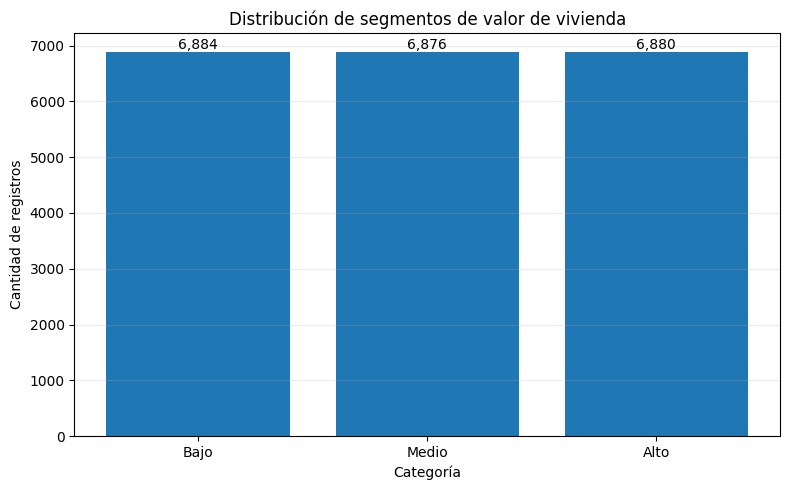

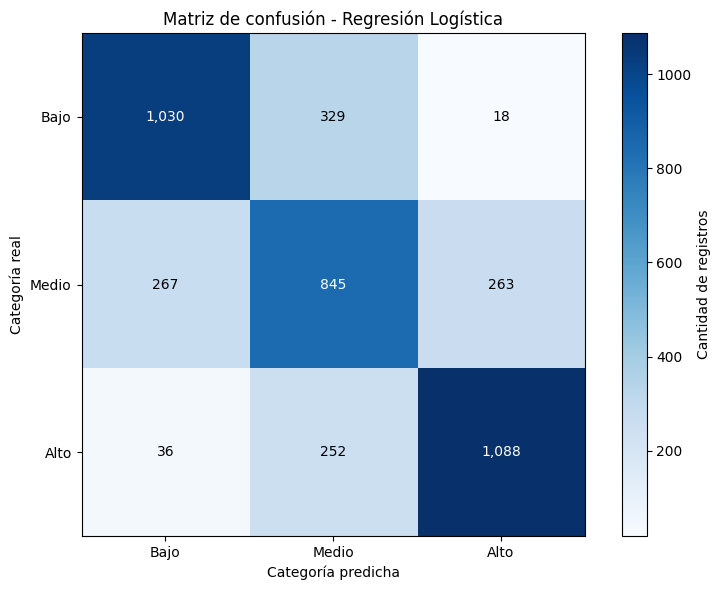

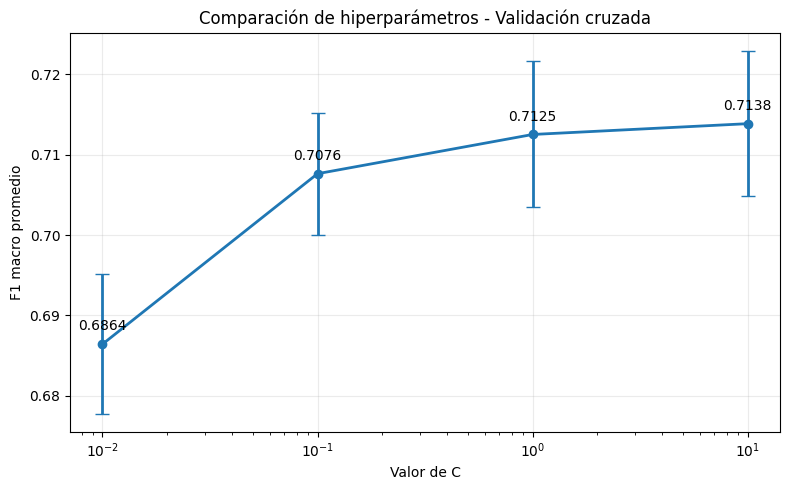


GRÁFICAS GENERADAS CORRECTAMENTE
- 01_distribucion_categorias.png
- 02_matriz_confusion.png
- 03_comparacion_hiperparametros.png

Ubicación: /workspaces/Machine-Learning/src/notebook/reportes/entrega_3/figuras


In [19]:

# 4. GENERACIÓN Y EXPORTACIÓN DE GRÁFICAS DE RESULTADOS

import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# Crear carpeta para almacenar las gráficas
CARPETA_GRAFICAS = ROOT / "src" / "notebook" / "reportes" / "entrega_3" / "figuras"
CARPETA_GRAFICAS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# GRÁFICA 1. DISTRIBUCIÓN DE LAS CATEGORÍAS
# ------------------------------------------------------------

distribucion = (
    df_modelo["Categoria_valor"]
    .value_counts()
    .reindex(["Bajo", "Medio", "Alto"])
)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    distribucion.index,
    distribucion.values
)

ax.set_title("Distribución de segmentos de valor de vivienda")
ax.set_xlabel("Categoría")
ax.set_ylabel("Cantidad de registros")
ax.grid(axis="y", alpha=0.25)

for barra, valor in zip(barras, distribucion.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
fig.savefig(
    CARPETA_GRAFICAS / "01_distribucion_categorias.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# GRÁFICA 2. MATRIZ DE CONFUSIÓN DEL MODELO OPTIMIZADO
# ------------------------------------------------------------

matriz = matriz_optimizada.values

fig, ax = plt.subplots(figsize=(8, 6))

imagen = ax.imshow(matriz, cmap="Blues")

ax.set_title("Matriz de confusión - Regresión Logística")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")

etiquetas = ["Bajo", "Medio", "Alto"]

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(etiquetas)
ax.set_yticklabels(etiquetas)

umbral = matriz.max() / 2

for fila in range(matriz.shape[0]):
    for columna in range(matriz.shape[1]):
        ax.text(
            columna,
            fila,
            f"{matriz[fila, columna]:,}",
            ha="center",
            va="center",
            color="white" if matriz[fila, columna] > umbral else "black"
        )

fig.colorbar(imagen, ax=ax, label="Cantidad de registros")

plt.tight_layout()
fig.savefig(
    CARPETA_GRAFICAS / "02_matriz_confusion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# GRÁFICA 3. COMPARACIÓN DE HIPERPARÁMETROS
# ------------------------------------------------------------

resultados_cv = busqueda_C.cv_results_

valores_C = [
    float(valor)
    for valor in resultados_cv["param_modelo__C"]
]

f1_promedio = resultados_cv["mean_test_score"]
desviacion = resultados_cv["std_test_score"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    valores_C,
    f1_promedio,
    yerr=desviacion,
    marker="o",
    capsize=5,
    linewidth=2
)

ax.set_xscale("log")
ax.set_title("Comparación de hiperparámetros - Validación cruzada")
ax.set_xlabel("Valor de C")
ax.set_ylabel("F1 macro promedio")
ax.grid(True, alpha=0.25)

for x, y in zip(valores_C, f1_promedio):
    ax.annotate(
        f"{y:.4f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.tight_layout()
fig.savefig(
    CARPETA_GRAFICAS / "03_comparacion_hiperparametros.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# CONFIRMACIÓN
# ------------------------------------------------------------

print("\nGRÁFICAS GENERADAS CORRECTAMENTE")

for archivo in sorted(CARPETA_GRAFICAS.glob("*.png")):
    print("-", archivo.name)

print("\nUbicación:", CARPETA_GRAFICAS)


## 4. Resumen automático y documento de hallazgos

En esta sección se genera automáticamente un archivo de texto con la información de la ejecución del experimento, incluyendo el dataset, el preprocesamiento, la configuración del modelo, las métricas obtenidas y la fecha de ejecución.

Adicionalmente, se documentan los principales hallazgos del modelo para responder la pregunta de negocio, considerando su desempeño, confiabilidad, limitaciones y posibles aplicaciones.

### 4.1. Generación automática del resumen de ejecución

El siguiente código recopila la información directamente de las variables y resultados generados durante la ejecución del notebook. El archivo de texto no se redacta manualmente.

In [18]:
from datetime import datetime
from pathlib import Path
import sys
import platform
import pandas as pd
import numpy as np
import sklearn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Verificar que existan los resultados necesarios
# ------------------------------------------------------------

variables_requeridas = [
    "DATASET",
    "SPLIT",
    "df_modelo",
    "columnas_predictoras",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "busqueda_C",
    "mejor_modelo",
    "predicciones_optimizadas",
    "ruta_modelo_optimizado"
]

faltantes = [
    variable
    for variable in variables_requeridas
    if variable not in globals()
]

if faltantes:
    raise RuntimeError(
        "No se puede generar el resumen. "
        f"Faltan las siguientes variables: {faltantes}"
    )

# ------------------------------------------------------------
# 2. Recuperar información de la ejecución
# ------------------------------------------------------------

fecha_ejecucion = datetime.now()

nombre_dataset = DATASET
split_dataset = SPLIT

filas_originales = len(df_modelo)
columnas_originales = len(df_modelo.columns)

variables = list(columnas_predictoras)
categorias = list(y_train.cat.categories)

cantidad_entrenamiento = len(X_train)
cantidad_prueba = len(X_test)

# Métricas calculadas sobre el conjunto de prueba
exactitud = accuracy_score(
    y_test,
    predicciones_optimizadas
)

f1_macro = f1_score(
    y_test,
    predicciones_optimizadas,
    average="macro"
)

f1_ponderado = f1_score(
    y_test,
    predicciones_optimizadas,
    average="weighted"
)

# Métricas detalladas por categoría
reporte_clasificacion = classification_report(
    y_test,
    predicciones_optimizadas,
    labels=categorias,
    output_dict=True,
    zero_division=0
)

# Matriz de confusión
matriz_confusion = confusion_matrix(
    y_test,
    predicciones_optimizadas,
    labels=categorias
)

# Mejor configuración encontrada
mejores_parametros = busqueda_C.best_params_
mejor_C = mejores_parametros["modelo__C"]
mejor_f1_validacion = busqueda_C.best_score_

# Parámetros efectivos del modelo
parametros_modelo = (
    mejor_modelo.named_steps["modelo"].get_params()
)

# Resultados de la búsqueda de hiperparámetros
tabla_busqueda = pd.DataFrame(
    busqueda_C.cv_results_
)[[
    "param_modelo__C",
    "mean_test_score",
    "std_test_score",
    "mean_train_score"
]].copy()

# ------------------------------------------------------------
# 3. Construir el contenido del archivo
# ------------------------------------------------------------

lineas = []

def agregar(texto=""):
    lineas.append(str(texto))

agregar("RESUMEN AUTOMÁTICO DE LA EJECUCIÓN")
agregar("ACTIVIDAD 3 - APRENDIZAJE SUPERVISADO")
agregar("=" * 75)
agregar(f"Fecha de ejecución: {fecha_ejecucion.strftime('%Y-%m-%d %H:%M:%S')}")
agregar(f"Python: {platform.python_version()}")
agregar(f"Pandas: {pd.__version__}")
agregar(f"NumPy: {np.__version__}")
agregar(f"Scikit-learn: {sklearn.__version__}")

agregar()
agregar("=" * 75)
agregar("1. PREGUNTA DE NEGOCIO")
agregar("=" * 75)

agregar(
    "¿Qué características socioeconómicas y geográficas permiten "
    "identificar si una zona residencial de California pertenece "
    "a un segmento de valor de vivienda bajo, medio o alto?"
)

agregar()
agregar("=" * 75)
agregar("2. DATASET Y PREPROCESAMIENTO")
agregar("=" * 75)

agregar(f"Dataset: {nombre_dataset}")
agregar(f"Split utilizado: {split_dataset}")
agregar(f"Registros: {filas_originales}")
agregar(f"Columnas del DataFrame transformado: {columnas_originales}")
agregar(f"Valores nulos: {int(df_modelo.isna().sum().sum())}")
agregar(f"Registros duplicados: {int(df_modelo.duplicated().sum())}")

agregar()
agregar("Preprocesamiento aplicado:")
agregar("- Renombrado de las columnas originales al español.")
agregar("- Creación de Categoria_valor mediante tres terciles de Valor_mediano_vivienda.")
agregar("- Categorías objetivo: Bajo, Medio y Alto.")
agregar("- Identificación de valores extremos mediante el método IQR.")
agregar("- Conservación de los valores extremos identificados.")
agregar("- Exclusión de Valor_mediano_vivienda de las variables predictoras para evitar fuga de información.")
agregar("- División estratificada: 80% entrenamiento y 20% prueba.")
agregar("- Uso de StandardScaler dentro del Pipeline de clasificación.")

agregar()
agregar("Variables predictoras:")
for variable in variables:
    agregar(f"- {variable}")

agregar(f"Variable objetivo: {y_train.name}")
agregar(f"Categorías: {', '.join(map(str, categorias))}")

agregar()
agregar("Distribución de categorías:")
for categoria, cantidad in y.value_counts().sort_index().items():
    agregar(f"- {categoria}: {cantidad}")

agregar()
agregar("División de los datos:")
agregar(f"- Entrenamiento: {cantidad_entrenamiento} registros")
agregar(f"- Prueba: {cantidad_prueba} registros")
agregar(f"- Proporción de prueba: {len(X_test) / (len(X_train) + len(X_test)):.0%}")
agregar("- random_state: 42")
agregar("- Estratificación: activada")

agregar()
agregar("=" * 75)
agregar("3. TIPO DE APRENDIZAJE Y ALGORITMO")
agregar("=" * 75)

agregar("Tipo de aprendizaje: Supervisado.")
agregar("Problema: Clasificación multiclase.")
agregar("Algoritmo: Regresión Logística (LogisticRegression).")
agregar("Preprocesamiento del modelo: StandardScaler.")
agregar("Estructura: Pipeline de Scikit-learn.")

agregar()
agregar("Parámetros efectivos del modelo:")
for parametro, valor in parametros_modelo.items():
    agregar(f"- {parametro}: {valor}")

agregar()
agregar("=" * 75)
agregar("4. CONFIGURACIÓN DE LA OPTIMIZACIÓN")
agregar("=" * 75)

agregar("Método: GridSearchCV")
agregar("Validación cruzada: StratifiedKFold")
agregar("Número de particiones: 5")
agregar("Métrica de selección: F1 macro")
agregar(f"Mejores parámetros: {mejores_parametros}")
agregar(f"Mejor valor de C: {mejor_C}")
agregar(f"Mejor F1 macro en validación cruzada: {mejor_f1_validacion:.4f}")

agregar()
agregar("Comparación de hiperparámetros:")
agregar(tabla_busqueda.to_string(index=False))

agregar()
agregar("=" * 75)
agregar("5. MÉTRICAS DEL MODELO OPTIMIZADO")
agregar("=" * 75)

agregar(f"Exactitud (Accuracy): {exactitud:.4f}")
agregar(f"F1 macro: {f1_macro:.4f}")
agregar(f"F1 ponderado: {f1_ponderado:.4f}")

agregar()
agregar("Resultados por categoría:")

for categoria in categorias:
    resultado = reporte_clasificacion[str(categoria)]

    agregar(f"\nCategoría: {categoria}")
    agregar(f"- Precisión: {resultado['precision']:.4f}")
    agregar(f"- Recall: {resultado['recall']:.4f}")
    agregar(f"- F1-score: {resultado['f1-score']:.4f}")
    agregar(f"- Registros: {int(resultado['support'])}")

agregar()
agregar("Matriz de confusión:")
agregar(
    pd.DataFrame(
        matriz_confusion,
        index=[f"Real {c}" for c in categorias],
        columns=[f"Predicho {c}" for c in categorias]
    ).to_string()
)

agregar()
agregar("=" * 75)
agregar("6. MODELO GENERADO")
agregar("=" * 75)

agregar(f"Archivo del modelo: {Path(ruta_modelo_optimizado).name}")
agregar(f"Ruta: {ruta_modelo_optimizado}")

agregar()
agregar("=" * 75)
agregar("7. NOTA SOBRE LA INTERPRETACIÓN")
agregar("=" * 75)

agregar(
    "Las categorías Bajo, Medio y Alto representan terciles relativos "
    "del valor mediano de vivienda del conjunto de datos. "
    "No constituyen rangos universales de precios ni una tasación individual."
)

agregar(
    "Los resultados corresponden a una evaluación sobre un conjunto "
    "de prueba separado y a una búsqueda de hiperparámetros mediante "
    "validación cruzada de cinco particiones."
)

agregar()
agregar("FIN DEL RESUMEN")

# ------------------------------------------------------------
# 4. Guardar el archivo TXT
# ------------------------------------------------------------

directorio_reportes = (
    ROOT / "src" / "notebook" / "reportes" / "entrega_3"
)

directorio_reportes.mkdir(
    parents=True,
    exist_ok=True
)

ruta_resumen = directorio_reportes / "resumen_modelo.txt"

contenido_resumen = "\n".join(lineas)

ruta_resumen.write_text(
    contenido_resumen,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5. Confirmar resultado
# ------------------------------------------------------------

print("RESUMEN GENERADO CORRECTAMENTE")
print("=" * 55)
print("Archivo:", ruta_resumen.name)
print("Ubicación:", ruta_resumen)
print("Tamaño:", f"{ruta_resumen.stat().st_size:,}", "bytes")
print("Fecha:", fecha_ejecucion.strftime("%Y-%m-%d %H:%M:%S"))

print("\nVista previa:")
print("\n".join(lineas[:20]))


RESUMEN GENERADO CORRECTAMENTE
Archivo: resumen_modelo.txt
Ubicación: /workspaces/Machine-Learning/src/notebook/reportes/entrega_3/resumen_modelo.txt
Tamaño: 5,173 bytes
Fecha: 2026-11-08 06:58:13

Vista previa:
RESUMEN AUTOMÁTICO DE LA EJECUCIÓN
ACTIVIDAD 3 - APRENDIZAJE SUPERVISADO
Fecha de ejecución: 2026-11-08 06:58:13
Python: 3.12.3
Pandas: 2.2.3
NumPy: 2.5.4
Scikit-learn: 1.9.1

1. PREGUNTA DE NEGOCIO
¿Qué características socioeconómicas y geográficas permiten identificar si una zona residencial de California pertenece a un segmento de valor de vivienda bajo, medio o alto?

2. DATASET Y PREPROCESAMIENTO
Dataset: BrianSuToronto/california_housing
Split utilizado: train
Registros: 20640
